# Thực nghiệm Random Agent và Rule-Based Agent trên Caro 11×11

Notebook thực hiện: khởi tạo môi trường, kiểm thử luật chơi, xây dựng/khởi tạo hai agent từ `src/`, chạy tournament có cân bằng lượt đi trước, thống kê kết quả, vẽ biểu đồ và xuất video MP4.

**Quy ước:** bàn cờ 11×11; `X = 1` đi trước, `O = -1`; thắng khi có ít nhất 5 quân liên tiếp theo hàng, cột hoặc hai đường chéo. Các nước đi được mã hóa thành số nguyên `row * 11 + col`.

## 1. Import và cấu hình

In [1]:
from pathlib import Path
import sys, os, time, random, shutil, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Nạp module từ đúng thư mục dự án và làm mới cache nếu kernel đã import bản cũ.
from src.caro_env import CaroEnv
from src.agents import RandomAgent, RuleBasedAgent
import src.tournament as tournament_module
importlib.reload(tournament_module)

# Kiểm tra đúng file Python đang được notebook sử dụng.
print("Tournament module:", tournament_module.__file__)
required_api = ("play_game", "run_matchup")
missing_api = [name for name in required_api if not callable(getattr(tournament_module, name, None))]
if missing_api:
    raise ImportError(
        f"src/tournament.py thiếu {missing_api}. Hãy thay file bằng bản trong gói đã sửa, "
        "sau đó chọn Kernel > Restart Kernel và chạy Run All."
    )
play_game = tournament_module.play_game
run_matchup = tournament_module.run_matchup

BOARD_SIZE = 11
WIN_LENGTH = 5
GAMES_PER_MATCHUP = 20   # Chạy nhanh; đổi thành 100 cho thực nghiệm chính thức
SEED = 42

RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
CHART_DIR = RESULTS_DIR / "charts"
VIDEO_DIR = RESULTS_DIR / "videos"
for folder in (TABLE_DIR, CHART_DIR, VIDEO_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Số ván mỗi cặp:", GAMES_PER_MATCHUP)

Tournament module: f:\TTNTNC\Caro\caro_ai_11x11\src\tournament.py
Project: f:\TTNTNC\Caro\caro_ai_11x11
Số ván mỗi cặp: 20


## 2. Kiểm tra môi trường Caro

In [2]:
env = CaroEnv(BOARD_SIZE, WIN_LENGTH)

print("Kích thước bàn:", env.board.shape)
print("Số nước đi hợp lệ ban đầu:", len(env.legal_actions()))

env.render()

Kích thước bàn: (11, 11)
Số nước đi hợp lệ ban đầu: 121
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  .  .  .  .  .  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .


'    0  1  2  3  4  5  6  7  8  9 10\n 0  .  .  .  .  .  .  .  .  .  .  .\n 1  .  .  .  .  .  .  .  .  .  .  .\n 2  .  .  .  .  .  .  .  .  .  .  .\n 3  .  .  .  .  .  .  .  .  .  .  .\n 4  .  .  .  .  .  .  .  .  .  .  .\n 5  .  .  .  .  .  .  .  .  .  .  .\n 6  .  .  .  .  .  .  .  .  .  .  .\n 7  .  .  .  .  .  .  .  .  .  .  .\n 8  .  .  .  .  .  .  .  .  .  .  .\n 9  .  .  .  .  .  .  .  .  .  .  .\n10  .  .  .  .  .  .  .  .  .  .  .'

## 3. Kiểm tra hai agent trả về hành động hợp lệ

In [3]:
env = CaroEnv(BOARD_SIZE, WIN_LENGTH)

agents_smoke_test = [
    RandomAgent(seed=SEED),
    RuleBasedAgent()
]

for agent in agents_smoke_test:
    action = agent.select_action(env)
    legal_actions = env.legal_actions()

    print(
        f"{agent.name}: "
        f"action={action}, "
        f"row={action // BOARD_SIZE}, "
        f"col={action % BOARD_SIZE}, "
        f"legal={action in legal_actions}"
    )

    assert action in legal_actions, (
        f"{agent.name} chọn nước đi không hợp lệ: {action}"
    )

Random: action=81, row=7, col=4, legal=True
Rule-Based: action=60, row=5, col=5, legal=True


## 4. Minh họa một ván đấu

In [4]:
demo = play_game(RandomAgent(SEED), RuleBasedAgent(), BOARD_SIZE, WIN_LENGTH, record=False)
print({k:v for k,v in demo.items() if k != "history"})

{'winner': -1, 'moves': 10, 'x_agent': 'Random', 'o_agent': 'Rule-Based', 'x_avg_ms': 0.0349399633705616, 'o_avg_ms': 12.400139961391687}


## 5. Chạy tournament

In [5]:
matchups = {
    "Random vs Random": (lambda seed: RandomAgent(seed=seed, name="Random A"),
                         lambda seed: RandomAgent(seed=seed, name="Random B")),
    "Rule-Based vs Random": (lambda seed: RuleBasedAgent(name="Rule-Based"),
                             lambda seed: RandomAgent(seed=seed, name="Random")),
    "Random vs Rule-Based": (lambda seed: RandomAgent(seed=seed, name="Random"),
                             lambda seed: RuleBasedAgent(name="Rule-Based")),
    "Rule-Based vs Rule-Based": (lambda seed: RuleBasedAgent(name="Rule-Based A"),
                                 lambda seed: RuleBasedAgent(name="Rule-Based B")),
}
all_results = []
for matchup_name, (factory_a, factory_b) in matchups.items():
    print(f"Đang chạy {matchup_name} ...")
    rows = run_matchup(factory_a, factory_b, games=GAMES_PER_MATCHUP,
                       board_size=BOARD_SIZE, win_length=WIN_LENGTH, seed=SEED)
    for row in rows:
        row["matchup"] = matchup_name
    all_results.extend(rows)

results_df = pd.DataFrame(all_results)
results_df.to_csv(TABLE_DIR / "game_logs.csv", index=False, encoding="utf-8-sig")
display(results_df.head())
print("Tổng số ván:", len(results_df))

Đang chạy Random vs Random ...
Đang chạy Rule-Based vs Random ...
Đang chạy Random vs Rule-Based ...
Đang chạy Rule-Based vs Rule-Based ...


,game,winner,moves,x_avg_ms,o_avg_ms,first_player,x_agent,o_agent,matchup
0,1,B,62,0.006377,0.004384,A,Random A,Random B,Random vs Random
1,2,B,67,0.003606,0.003573,B,Random B,Random A,Random vs Random
2,3,A,69,0.003523,0.003762,A,Random A,Random B,Random vs Random
3,4,A,28,0.003636,0.003636,B,Random B,Random A,Random vs Random
4,5,A,89,0.003582,0.003761,A,Random A,Random B,Random vs Random


Tổng số ván: 80


## 6. Bảng tổng hợp kết quả

In [6]:
summary_rows = []
for matchup_name, group in results_df.groupby("matchup", sort=False):
    a_wins = int((group["winner"] == "A").sum())
    b_wins = int((group["winner"] == "B").sum())
    draws = int((group["winner"] == "Draw").sum())
    n = len(group)
    summary_rows.append({
        "Matchup": matchup_name, "Games": n,
        "A wins": a_wins, "B wins": b_wins, "Draws": draws,
        "A win rate (%)": round(100*a_wins/n, 2),
        "B win rate (%)": round(100*b_wins/n, 2),
        "Draw rate (%)": round(100*draws/n, 2),
        "Avg moves": round(group["moves"].mean(), 2),
        "Avg X decision (ms)": round(group["x_avg_ms"].mean(), 3),
        "Avg O decision (ms)": round(group["o_avg_ms"].mean(), 3),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLE_DIR / "tournament_summary.csv", index=False, encoding="utf-8-sig")
display(summary_df)

,Matchup,Games,A wins,B wins,Draws,A win rate (%),B win rate (%),Draw rate (%),Avg moves,Avg X decision (ms),Avg O decision (ms)
0,Random vs Random,20,8,12,0,40.0,60.0,0.0,67.7,0.005,0.004
1,Rule-Based vs Random,20,20,0,0,100.0,0.0,0.0,10.0,8.455,10.261
2,Random vs Rule-Based,20,0,20,0,0.0,100.0,0.0,9.8,9.944,12.602
3,Rule-Based vs Rule-Based,20,0,0,20,0.0,0.0,100.0,121.0,9.289,9.601


## 7. Phân tích hiệu năng theo từng vai trò

In [7]:
performance_df = (results_df.groupby("matchup")
                  .agg(games=("game","count"),
                       avg_moves=("moves","mean"),
                       avg_x_ms=("x_avg_ms","mean"),
                       avg_o_ms=("o_avg_ms","mean"))
                  .reset_index())
performance_df[["avg_moves","avg_x_ms","avg_o_ms"]] = performance_df[["avg_moves","avg_x_ms","avg_o_ms"]].round(3)
performance_df.to_csv(TABLE_DIR / "agent_performance.csv", index=False, encoding="utf-8-sig")
display(performance_df)

,matchup,games,avg_moves,avg_x_ms,avg_o_ms
0,Random vs Random,20,67.7,0.005,0.004
1,Random vs Rule-Based,20,9.8,9.944,12.602
2,Rule-Based vs Random,20,10.0,8.455,10.261
3,Rule-Based vs Rule-Based,20,121.0,9.289,9.601


## 8. Biểu đồ tỷ lệ thắng và số nước trung bình

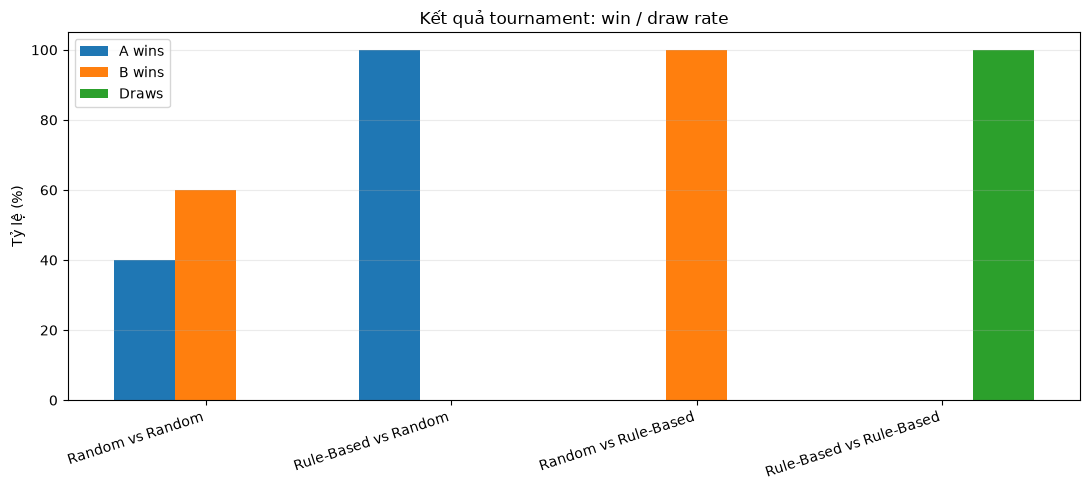

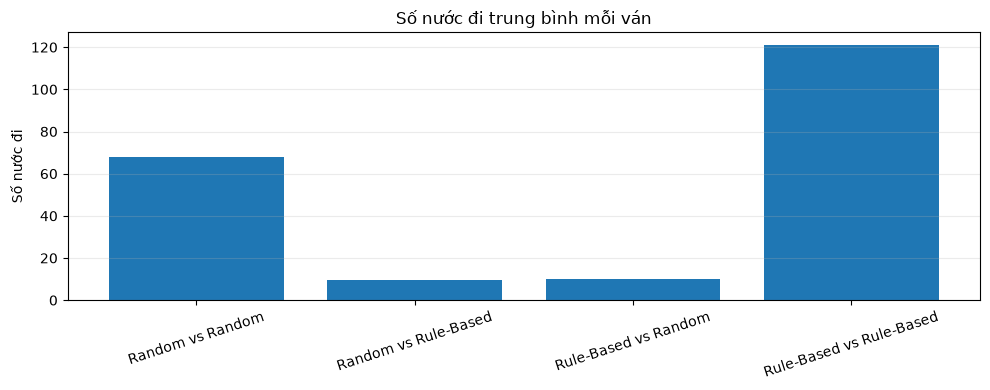

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(summary_df))
w = 0.25
ax.bar(x-w, summary_df["A win rate (%)"], width=w, label="A wins")
ax.bar(x, summary_df["B win rate (%)"], width=w, label="B wins")
ax.bar(x+w, summary_df["Draw rate (%)"], width=w, label="Draws")
ax.set_xticks(x, summary_df["Matchup"], rotation=18, ha="right")
ax.set_ylabel("Tỷ lệ (%)")
ax.set_title("Kết quả tournament: win / draw rate")
ax.legend()
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "win_draw_rates.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(performance_df["matchup"], performance_df["avg_moves"])
ax.set_ylabel("Số nước đi")
ax.set_title("Số nước đi trung bình mỗi ván")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "average_moves.png", dpi=160)
plt.show()

## 9. Hàm ghi video MP4

In [9]:
import matplotlib.animation as animation

def save_game_mp4(agent_x, agent_o, filename, seed=42, fps=2):
    # Ghi lại trạng thái sau mỗi nước đi.
    game = play_game(agent_x, agent_o, BOARD_SIZE, WIN_LENGTH, record=True)
    history = game["history"]
    ffmpeg_path = shutil.which("ffmpeg")
    if ffmpeg_path is None:
        try:
            import imageio_ffmpeg
            ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()
        except ImportError as exc:
            raise RuntimeError("Thiếu FFmpeg. Hãy cài imageio-ffmpeg bằng pip install imageio-ffmpeg.") from exc

    fig, ax = plt.subplots(figsize=(7, 7))
    fig.subplots_adjust(top=0.88, bottom=0.08)
    grid = np.arange(-0.5, BOARD_SIZE, 1)
    ax.set_xticks(np.arange(BOARD_SIZE))
    ax.set_yticks(np.arange(BOARD_SIZE))
    ax.set_xlim(-0.5, BOARD_SIZE-0.5)
    ax.set_ylim(BOARD_SIZE-0.5, -0.5)
    ax.set_xticks(grid, minor=True)
    ax.set_yticks(grid, minor=True)
    ax.grid(which="minor", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_aspect("equal")
    ax.set_title("Caro 11×11 | X: " + agent_x.name + "  vs  O: " + agent_o.name)

    scat_x = ax.scatter([], [], s=180, marker="o", c="black", label="X")
    scat_o = ax.scatter([], [], s=180, marker="o", facecolors="white", edgecolors="black", linewidths=2, label="O")
    status = fig.text(0.5, 0.93, "", ha="center", fontsize=11)

    def update(frame):
        board = history[frame]
        xr, xc = np.where(board == 1)
        or_, oc = np.where(board == -1)
        scat_x.set_offsets(np.c_[xc, xr] if len(xr) else np.empty((0,2)))
        scat_o.set_offsets(np.c_[oc, or_] if len(or_) else np.empty((0,2)))
        move_no = frame
        if frame == len(history)-1:
            result = "Hòa" if game["winner"] is None else ("X thắng" if game["winner"] == 1 else "O thắng")
            status.set_text(f"Kết thúc: {result} | {game['moves']} nước")
        else:
            status.set_text(f"Nước đi: {move_no}/{game['moves']} | " + ("X" if move_no % 2 == 0 else "O") + " vừa đi")
        return scat_x, scat_o, status

    ani = animation.FuncAnimation(fig, update, frames=len(history), interval=500, blit=False)
    writer = animation.FFMpegWriter(fps=fps, metadata={"title": "Caro AI 11x11"})
    old_path = animation.writers.is_available("ffmpeg")
    # Matplotlib lấy executable từ PATH; bổ sung thư mục ffmpeg nếu imageio-ffmpeg cung cấp.
    import os
    ffmpeg_dir = str(Path(ffmpeg_path).parent)
    os.environ["PATH"] = ffmpeg_dir + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["animation.ffmpeg_path"] = ffmpeg_path
    out_path = VIDEO_DIR / filename
    ani.save(out_path, writer=writer, dpi=100)
    plt.close(fig)
    return {"video": str(out_path), "winner": game["winner"], "moves": game["moves"]}

## 10. Xuất video cho bốn cặp agent

In [10]:
import sys
import subprocess

# Cài imageio-ffmpeg vào đúng môi trường Kernel hiện tại
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "imageio-ffmpeg"
])

print("Cài đặt imageio-ffmpeg thành công!")
video_specs = [
    ("random_vs_random.mp4", lambda: RandomAgent(SEED, "Random X"), lambda: RandomAgent(SEED+1, "Random O")),
    ("rulebase_vs_random.mp4", lambda: RuleBasedAgent("Rule-Based X"), lambda: RandomAgent(SEED+2, "Random O")),
    ("random_vs_rulebase.mp4", lambda: RandomAgent(SEED+3, "Random X"), lambda: RuleBasedAgent("Rule-Based O")),
    ("rulebase_vs_rulebase.mp4", lambda: RuleBasedAgent("Rule-Based X"), lambda: RuleBasedAgent("Rule-Based O")),
]
video_results = []
for filename, make_x, make_o in video_specs:
    print("Đang render:", filename)
    video_results.append(save_game_mp4(make_x(), make_o(), filename))
display(pd.DataFrame(video_results))

Cài đặt imageio-ffmpeg thành công!
Đang render: random_vs_random.mp4
Đang render: rulebase_vs_random.mp4
Đang render: random_vs_rulebase.mp4
Đang render: rulebase_vs_rulebase.mp4


,video,winner,moves
0,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ra...,-1.0,92
1,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ru...,1.0,9
2,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ra...,-1.0,10
3,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ru...,NaN,121


## 11. Kiểm tra và tải các kết quả

In [11]:
print("CSV tables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p)
print("\nCharts:")
for p in sorted(CHART_DIR.glob("*.png")):
    print(" -", p)
print("\nVideos:")
for p in sorted(VIDEO_DIR.glob("*.mp4")):
    print(f" - {p} ({p.stat().st_size/1024/1024:.2f} MB)")

CSV tables:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\agent_performance.csv
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\game_logs.csv
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\tournament_summary.csv

Charts:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\charts\average_moves.png
 - f:\TTNTNC\Caro\caro_ai_11x11\results\charts\win_draw_rates.png

Videos:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_random_20261107_155731.mp4 (0.04 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_20261107_011619.mp4 (0.08 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_20261109_121359.mp4 (0.04 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_20261109_121406.mp4 (0.04 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_20261109_121748.mp4 (0.05 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_20261109_122457.mp4 (0.04 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\human_vs_rulebase_202611

## Player vs Agent

In [ ]:

# ============================================================
# CARO 11x11 - HUMAN VS AI
# FULL NOTEBOOK CELL
#
# - Random Agent / Rule-Based Agent
# - Auto reset when changing Agent
# - Auto reset when pressing Start
# - Rebuild all 121 board buttons for every new game
# - Ignore AI results from previous games
# - Human: X (1)
# - AI: O (-1)
# - Five consecutive stones to win
# - Export MP4 when game ends
# - Clear displayed board after exporting
# - Preserve previous MP4 files
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT
# ============================================================

import sys
import subprocess
import importlib.util
import random
import asyncio
import time

from pathlib import Path
from datetime import datetime


required_packages = {
    "numpy": "numpy",
    "ipywidgets": "ipywidgets",
    "matplotlib": "matplotlib",
    "imageio": "imageio",
    "imageio_ffmpeg": "imageio-ffmpeg"
}

for module_name, package_name in required_packages.items():

    if importlib.util.find_spec(module_name) is None:

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            package_name
        ])


import numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt
import imageio.v2 as imageio

from IPython.display import display, clear_output


# ============================================================
# 2. FIND PROJECT ROOT
# ============================================================

PROJECT_ROOT = None

for path in [Path.cwd(), *Path.cwd().parents]:

    if (path / "src" / "caro_env.py").exists():

        PROJECT_ROOT = path
        break


if PROJECT_ROOT is None:

    raise FileNotFoundError(
        "Không tìm thấy src/caro_env.py. "
        "Hãy mở Notebook bên trong thư mục caro_ai_11x11."
    )


if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(0, str(PROJECT_ROOT))


print("Project:", PROJECT_ROOT)


# ============================================================
# 3. IMPORT PROJECT MODULES
# ============================================================

from src.caro_env import CaroEnv
from src.agents.random_agent import RandomAgent
from src.agents.rule_based_agent import RuleBasedAgent


# ============================================================
# 4. CONFIGURATION
# ============================================================

BOARD_SIZE = 11
WIN_LENGTH = 5

VIDEO_DIR = PROJECT_ROOT / "results" / "videos"
VIDEO_DIR.mkdir(parents=True, exist_ok=True)

CELL_SIZE = "42px"
EMPTY_COLOR = "#eeeeee"
X_COLOR = "#b8d8ff"
O_COLOR = "#ffcccc"


# ============================================================
# 5. CREATE MAIN WIDGETS
# ============================================================

agent_selector = widgets.Dropdown(
    options=[
        ("Random Agent", "random"),
        ("Rule-Based Agent", "rulebase")
    ],
    value="rulebase",
    description="Đối thủ:",
    style={
        "description_width": "initial"
    },
    layout=widgets.Layout(
        width="350px"
    )
)


start_button = widgets.Button(
    description="Bắt đầu trận đấu",
    button_style="success",
    icon="play",
    layout=widgets.Layout(
        width="180px"
    )
)


status = widgets.HTML(
    value="<b>Đang khởi tạo...</b>"
)


video_output = widgets.Output()


# Output riêng để thay thế bàn cờ cũ
board_area = widgets.Output()


# ============================================================
# 6. GAME STATE
# ============================================================

game = {

    "env": None,
    "agent": None,
    "agent_type": None,

    "history": [],

    "finished": True,
    "winner": 0,

    "ai_thinking": False,

    "round_id": 0,

    "video_path": None,

    "ai_task": None
}


# ============================================================
# 7. DYNAMIC BOARD WIDGETS
# ============================================================

buttons = []
board_widget = None


def build_board():

    global buttons, board_widget

    # Tạo danh sách nút mới hoàn toàn
    new_buttons = []

    for r in range(BOARD_SIZE):

        row_buttons = []

        for c in range(BOARD_SIZE):

            btn = widgets.Button(
                description="",
                layout=widgets.Layout(
                    width=CELL_SIZE,
                    height=CELL_SIZE,
                    padding="0px",
                    margin="0px"
                ),
                style={
                    "font_weight": "bold",
                    "font_size": "16px",
                    "button_color": EMPTY_COLOR
                }
            )

            btn.on_click(
                lambda b, r=r, c=c: human_move(r, c)
            )

            row_buttons.append(btn)

        new_buttons.append(row_buttons)


    buttons = new_buttons

    board_widget = widgets.GridBox(

        children=[
            btn
            for row in buttons
            for btn in row
        ],

        layout=widgets.Layout(
            grid_template_columns=(
                f"repeat({BOARD_SIZE}, {CELL_SIZE})"
            ),
            grid_template_rows=(
                f"repeat({BOARD_SIZE}, {CELL_SIZE})"
            ),
            grid_gap="2px",
            width="fit-content"
        )
    )


    # Xóa widget bàn cờ trước và thay bằng widget mới
    with board_area:

        clear_output(wait=True)

        display(board_widget)


# ============================================================
# 8. CREATE AGENT
# ============================================================

def create_agent(agent_type):

    if agent_type == "random":

        seed = random.randint(0, 1000000)

        try:

            return RandomAgent(
                seed=seed,
                name="Random Agent"
            )

        except TypeError:

            try:

                return RandomAgent(seed=seed)

            except TypeError:

                return RandomAgent()


    if agent_type == "rulebase":

        try:

            return RuleBasedAgent(
                name="Rule-Based Agent"
            )

        except TypeError:

            return RuleBasedAgent()


    raise ValueError(
        f"Agent không hợp lệ: {agent_type}"
    )


# ============================================================
# 9. CHECK FIVE CONSECUTIVE STONES
# ============================================================

def check_five(board, player):

    directions = [
        (0, 1),
        (1, 0),
        (1, 1),
        (1, -1)
    ]

    for r in range(BOARD_SIZE):

        for c in range(BOARD_SIZE):

            if board[r, c] != player:
                continue

            for dr, dc in directions:

                count = 1

                for i in range(1, WIN_LENGTH):

                    nr = r + dr * i
                    nc = c + dc * i

                    if not (
                        0 <= nr < BOARD_SIZE
                        and 0 <= nc < BOARD_SIZE
                    ):
                        break

                    if board[nr, nc] == player:

                        count += 1

                    else:

                        break

                if count >= WIN_LENGTH:

                    return True

    return False


# ============================================================
# 10. UPDATE BOARD DISPLAY
# ============================================================

def update_board():

    env = game["env"]

    if env is None:
        return

    if len(buttons) != BOARD_SIZE:
        return

    for r in range(BOARD_SIZE):

        for c in range(BOARD_SIZE):

            value = int(env.board[r, c])

            btn = buttons[r][c]

            if value == 1:

                btn.description = "X"
                btn.style.button_color = X_COLOR

            elif value == -1:

                btn.description = "O"
                btn.style.button_color = O_COLOR

            else:

                btn.description = ""
                btn.style.button_color = EMPTY_COLOR


            btn.disabled = (
                game["finished"]
                or game["ai_thinking"]
                or value != 0
            )


# ============================================================
# 11. RENDER VIDEO FRAME
# ============================================================

def render_frame(board, title):

    fig, ax = plt.subplots(
        figsize=(7, 7),
        dpi=100
    )

    ax.set_xlim(-0.5, BOARD_SIZE - 0.5)
    ax.set_ylim(BOARD_SIZE - 0.5, -0.5)

    ax.set_xticks(range(BOARD_SIZE))
    ax.set_yticks(range(BOARD_SIZE))

    ax.set_xticks(
        np.arange(-0.5, BOARD_SIZE, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, BOARD_SIZE, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        linewidth=1
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    for r in range(BOARD_SIZE):

        for c in range(BOARD_SIZE):

            value = board[r, c]

            if value == 1:

                ax.text(
                    c,
                    r,
                    "X",
                    ha="center",
                    va="center",
                    fontsize=17,
                    fontweight="bold",
                    color="blue"
                )

            elif value == -1:

                ax.text(
                    c,
                    r,
                    "O",
                    ha="center",
                    va="center",
                    fontsize=17,
                    fontweight="bold",
                    color="red"
                )


    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    fig.tight_layout()

    fig.canvas.draw()

    frame = np.asarray(
        fig.canvas.buffer_rgba()
    )[:, :, :3].copy()

    plt.close(fig)

    return frame


# ============================================================
# 12. EXPORT VIDEO
# ============================================================

def export_video():

    env = game["env"]

    if env is None:
        return None

    winner = game["winner"]

    if winner == 1:

        result = "HUMAN X WINS"

    elif winner == -1:

        result = "AI O WINS"

    else:

        result = "DRAW"


    # Copy snapshots to protect history
    snapshots = [
        board.copy()
        for board in game["history"]
    ]

    final_board = env.board.copy()

    frames = []

    for i, board in enumerate(snapshots):

        frames.append(
            render_frame(
                board,
                f"CARO 11x11 | MOVE {i}"
            )
        )


    final_frame = render_frame(
        final_board,
        f"CARO 11x11 | {result}"
    )

    frames.extend(
        [final_frame] * 8
    )


    timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S_%f"
    )

    filename = (
        f"caro_{game['agent_type']}_{timestamp}.mp4"
    )

    video_path = VIDEO_DIR / filename


    try:

        imageio.mimsave(
            str(video_path),
            frames,
            fps=2,
            codec="libx264",
            quality=8,
            macro_block_size=16
        )

        game["video_path"] = video_path

        with video_output:

            clear_output(wait=True)

            print("VIDEO EXPORTED SUCCESSFULLY")
            print("File:", video_path)
            print("Result:", result)
            print("Number of frames:", len(frames))

        return video_path


    except Exception as e:

        with video_output:

            clear_output(wait=True)

            print("VIDEO EXPORT ERROR:")
            print(repr(e))

        return None


# ============================================================
# 13. FINISH GAME
# ============================================================

def finish_game(winner):

    if game["finished"]:
        return

    game["finished"] = True
    game["winner"] = winner
    game["ai_thinking"] = False


    # Disable all cells before exporting
    update_board()


    # Export video BEFORE clearing board
    video_path = export_video()


    if winner == 1:

        result = "NGƯỜI CHƠI X THẮNG!"
        color = "blue"

    elif winner == -1:

        result = "AI O THẮNG!"
        color = "red"

    else:

        result = "TRẬN ĐẤU HÒA!"
        color = "gray"


    # Clear displayed board after video export
    clear_board_ui()


    if video_path:

        status.value = (
            f"<h2 style='color:{color}'>{result}</h2>"
            "<b>Bàn cờ đã được xóa.</b><br>"
            f"Video đã lưu: <code>{video_path.name}</code>"
        )

    else:

        status.value = (
            f"<h2 style='color:{color}'>{result}</h2>"
            "<b>Bàn cờ đã được xóa.</b><br>"
            "Không thể xuất video. Kiểm tra thông báo lỗi."
        )


# ============================================================
# 14. CLEAR DISPLAYED BOARD
# ============================================================

def clear_board_ui():

    for row in buttons:

        for btn in row:

            btn.description = ""
            btn.style.button_color = EMPTY_COLOR
            btn.disabled = True


# ============================================================
# 15. CHECK GAME RESULT
# ============================================================

def check_game_result(player, done=False):

    env = game["env"]

    if env is None:
        return True


    if check_five(env.board, player):

        finish_game(player)
        return True


    if done:

        winner = int(getattr(env, "winner", 0))

        finish_game(winner)
        return True


    if len(env.legal_actions()) == 0:

        finish_game(0)
        return True


    return False


# ============================================================
# 16. AI ASYNC MOVE
# ============================================================

async def ai_move_async():

    env = game["env"]
    agent = game["agent"]

    if env is None or agent is None:
        return

    if game["finished"]:
        return

    if game["ai_thinking"]:
        return

    if env.current_player != -1:
        return


    # Store session identity
    current_round = game["round_id"]

    game["ai_thinking"] = True

    update_board()

    status.value = (
        "<b style='color:orange'>AI đang suy nghĩ...</b>"
    )


    try:

        legal_actions = env.legal_actions()

        if not legal_actions:

            if game["round_id"] == current_round:

                game["ai_thinking"] = False
                finish_game(0)

            return


        # Clone environment for agent
        env_snapshot = env.clone()


        # Run AI outside the event loop
        action = await asyncio.to_thread(
            agent.select_action,
            env_snapshot
        )


        # Ignore result from old game
        if game["round_id"] != current_round:
            return

        if game["env"] is not env:
            return

        if game["finished"]:
            return


        # Check current player again
        if env.current_player != -1:
            return


        # Validate action
        legal_actions = env.legal_actions()

        if not legal_actions:

            game["ai_thinking"] = False
            finish_game(0)
            return


        if action not in legal_actions:

            action = random.choice(legal_actions)


        # Apply AI action
        _, reward, done, info = env.step(action)


        # Save snapshot
        game["history"].append(
            env.board.copy()
        )


        game["ai_thinking"] = False


        if check_game_result(-1, done):
            return


        update_board()

        status.value = (
            "<b style='color:blue'>Đến lượt bạn (X)</b>"
        )


    except Exception as e:

        if game["round_id"] == current_round:

            game["ai_thinking"] = False

            update_board()

            status.value = (
                "<b style='color:red'>AI ERROR:</b> "
                + str(e)
            )

            print("AI ERROR:", repr(e))


# ============================================================
# 17. START AI TASK
# ============================================================

def ai_move():

    if game["finished"]:
        return

    if game["ai_thinking"]:
        return

    try:

        loop = asyncio.get_running_loop()

        game["ai_task"] = loop.create_task(
            ai_move_async()
        )

    except RuntimeError as e:

        status.value = (
            "<b style='color:red'>"
            "Không tìm thấy Async Event Loop. "
            "Hãy chạy trong Jupyter Notebook."
            "</b>"
        )

        print(repr(e))


# ============================================================
# 18. HUMAN MOVE
# ============================================================

def human_move(r, c):

    env = game["env"]

    if env is None:
        return

    if game["finished"]:
        return

    if game["ai_thinking"]:
        return

    if env.current_player != 1:
        return


    # Check bounds
    if not (
        0 <= r < BOARD_SIZE
        and 0 <= c < BOARD_SIZE
    ):
        return


    # Do not overwrite existing stone
    if env.board[r, c] != 0:
        return


    action = r * BOARD_SIZE + c

    if action not in env.legal_actions():
        return


    current_round = game["round_id"]


    # Apply human move
    _, reward, done, info = env.step(action)


    # Make sure session was not replaced
    if game["round_id"] != current_round:
        return


    game["history"].append(
        env.board.copy()
    )


    if check_game_result(1, done):
        return


    update_board()

    status.value = (
        "<b style='color:orange'>AI đang suy nghĩ...</b>"
    )

    ai_move()


# ============================================================
# 19. RESET ENTIRE GAME
# ============================================================

def reset_game(agent_type=None):

    # Invalidate all old AI results
    game["round_id"] += 1

    game["finished"] = True
    game["ai_thinking"] = False


    if agent_type is None:

        agent_type = agent_selector.value


    # Create a completely new environment
    new_env = CaroEnv(
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH
    )

    new_env.reset()


    # Verify environment reset
    if np.count_nonzero(new_env.board) != 0:

        raise RuntimeError(
            "Không thể xóa bàn cờ trong môi trường!"
        )


    # Create new Agent
    new_agent = create_agent(agent_type)


    # Replace all game state
    game["env"] = new_env
    game["agent"] = new_agent
    game["agent_type"] = agent_type

    game["history"] = [
        new_env.board.copy()
    ]

    game["winner"] = 0
    game["video_path"] = None

    game["finished"] = False
    game["ai_thinking"] = False
    game["ai_task"] = None


    # Rebuild all 121 UI buttons
    build_board()


    # Clear previous video message only
    # Existing MP4 files are preserved
    with video_output:

        clear_output(wait=True)


    status.value = (
        "<h3 style='color:blue'>TRẬN ĐẤU MỚI!</h3>"
        "<b>Bạn: X | AI: O</b><br>"
        "Đến lượt bạn. Hãy chọn một ô."
    )


    print("----------------------------------")
    print("NEW GAME")
    print("Agent:", agent_type)
    print("Game ID:", game["round_id"])
    print("Occupied cells:", np.count_nonzero(new_env.board))
    print("History:", len(new_env.history))
    print("----------------------------------")


# ============================================================
# 20. START BUTTON
# ============================================================

def start_game(_):

    reset_game(
        agent_selector.value
    )


# ============================================================
# 21. AUTO RESET WHEN AGENT CHANGES
# ============================================================

def on_agent_change(change):

    if change["name"] != "value":
        return

    if change["new"] == change["old"]:
        return


    print(
        "Agent changed:",
        change["new"]
    )


    # Automatically reset entire game
    reset_game(
        change["new"]
    )


# ============================================================
# 22. REGISTER EVENTS
# ============================================================

agent_selector.observe(
    on_agent_change,
    names="value"
)

start_button.on_click(
    start_game
)


# ============================================================
# 23. DISPLAY INTERFACE
# ============================================================

main_ui = widgets.VBox([

    widgets.HTML(
        "<h2>CARO 11x11 - HUMAN VS AI</h2>"
    ),

    widgets.HBox([
        agent_selector,
        start_button
    ]),

    status,

    board_area,

    video_output

])


display(main_ui)


# ============================================================
# 24. INITIALIZE FIRST GAME
# ============================================================

reset_game(
    agent_selector.value
)


print("====================================")
print("CARO 11x11 - READY")
print("Human: X")
print("AI: O")
print("Win condition: 5 consecutive stones")
print("Auto reset: ENABLED")
print("Video directory:", VIDEO_DIR)
print("====================================")


Project: f:\TTNTNC\Caro\caro_ai_11x11


----------------------------------
NEW GAME
Agent: rulebase
Game ID: 1
Occupied cells: 0
History: 0
----------------------------------
CARO 11x11 - READY
Human: X
AI: O
Win condition: 5 consecutive stones
Auto reset: ENABLED
Video directory: f:\TTNTNC\Caro\caro_ai_11x11\results\videos


## 12. Nhận xét và giới hạn phương pháp

- Random Agent chọn ngẫu nhiên trong tập nước đi hợp lệ; do đó kết quả phụ thuộc seed.
- Rule-Based Agent sử dụng heuristic cửa sổ 5 ô, ưu tiên thắng ngay, chặn nước thắng đối thủ, sau đó cân bằng điểm tấn công/phòng thủ và ưu tiên gần trung tâm.
- Tournament đổi bên X/O luân phiên để giảm thiên lệch do quyền đi trước.
- Thời gian quyết định được đo ở cấp Python trên máy chạy notebook; không nên so sánh giữa các máy khác cấu hình.
- Rule-Based hiện là baseline heuristic có thể giải thích, chưa phải thuật toán tìm kiếm sâu như Minimax/MCTS.
- Khi đưa số liệu vào báo cáo, cần chạy toàn bộ notebook và sử dụng đúng các CSV/biểu đồ được sinh ra từ lần chạy đó.